# Plotting results

## Librairies

In [1]:
import io
import os
import re
import sys

In [2]:
import pickle
import time
from timeit import default_timer as timer

import numpy as np
import random

In [3]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

## Plots

In [4]:
# Baseline results
baselines_d = {'banking': {'last' : 67.11, 'mean' : 84.35},
               'emotion': {'last' : 55.25, 'mean' : 63.70},
               'spam':    {'last' : 94.33, 'mean' : 95.66},
              }

In [5]:
# plot function by pooling strategy
def plot_by_ps(dataset, pooling_strategy, results_d):

    dims = list(results_d.keys())
    dims.sort()

    acc_bs = baselines_d[dataset][pooling_strategy]

    acc_esn = np.array([results_d[x]['recurrent_layer'][0] for x in dims])
    std_esn = np.array([results_d[x]['recurrent_layer'][1] for x in dims])

    acc_ll = np.array([results_d[x]['linear_layer'][0] for x in dims])
    std_ll = np.array([results_d[x]['linear_layer'][1] for x in dims])


    fig = plt.figure(figsize=(8, 4.5))

    ax = fig.add_subplot(111)

    # Baselines
    ax.axhline(y=acc_bs, linestyle='--', linewidth=3, color='grey', label=f'baseline ({pooling_strategy})', alpha=1)

    # ESNs
    ax.errorbar(dims, acc_esn, std_esn, color='C0', elinewidth=1, linewidth=2, label=f'ESN ({pooling_strategy})', marker='o', alpha=1)
    ax.fill_between(dims, acc_esn-std_esn, acc_esn+std_esn, alpha=0.2)
    # ax.plot(dims, acc_esn, color='C0', linewidth=3, label=f'ESN ({pooling_strategy})', marker='o', alpha=1)

    # Linear Layer
    ax.errorbar(dims, acc_ll, std_ll, color='C1', elinewidth=1, linewidth=2, label=f'LL ({pooling_strategy})', marker='o', alpha=1)
    ax.fill_between(dims, acc_ll-std_ll, acc_ll+std_ll, alpha=0.2)
    # ax.plot(dims, acc_ll, color='C1', linewidth=3, label=f'LL ({pooling_strategy})', marker='o', alpha=1)

    ax.set_title(dataset.upper() + f' ({pooling_strategy})', fontsize=15)
    ax.set_ylabel('test accuracy', fontsize=15)
    ax.set_xlabel('hidden dimension', fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

    # change legend order
    handles,labels = ax.get_legend_handles_labels()
    handles = [handles[0], handles[2], handles[1]]
    labels = [labels[0], labels[2], labels[1]]

    plt.legend(handles, labels, loc='lower center', prop={'size': 12}, ncol=3, bbox_to_anchor=(0.5, -0.35))
    plt.savefig('plots/' + dataset + '-' + pooling_strategy + '.pdf', bbox_inches = 'tight')

RESULTS FILE: banking_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: banking_results_esn_uniform_mean-pooling_FINAL.pkl
RESULTS FILE: emotion_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: emotion_results_esn_uniform_mean-pooling_FINAL.pkl
RESULTS FILE: spam_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: spam_results_esn_uniform_mean-pooling_FINAL.pkl


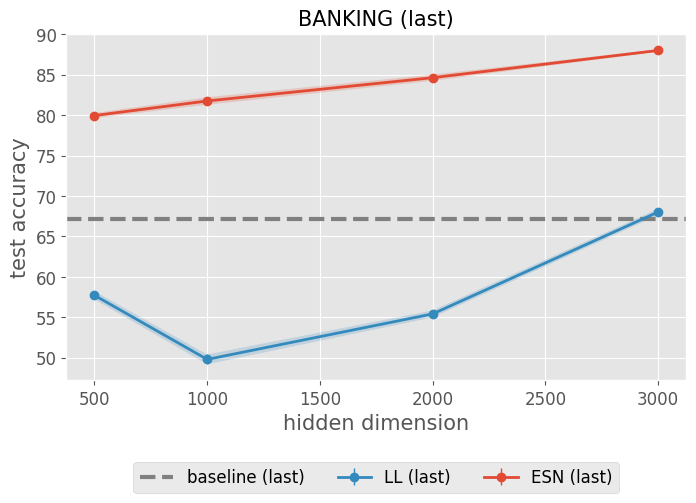

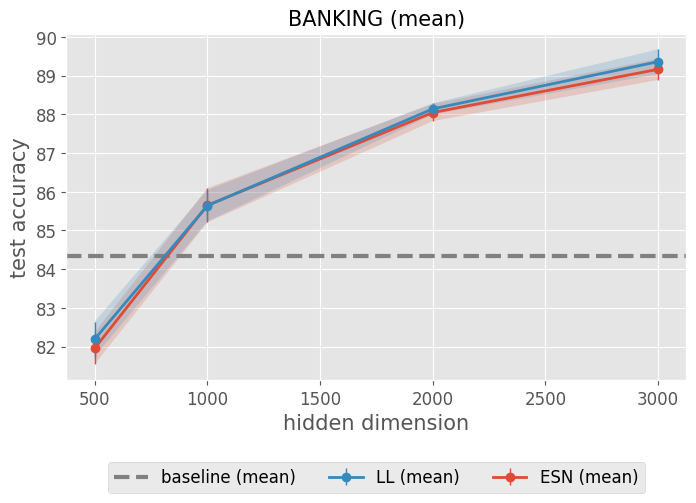

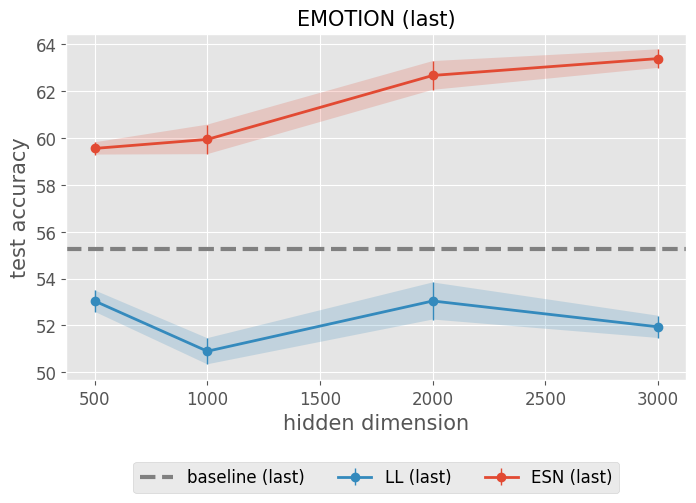

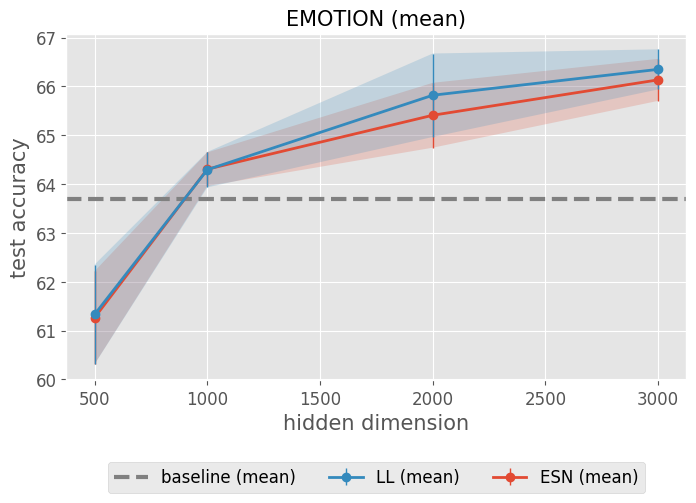

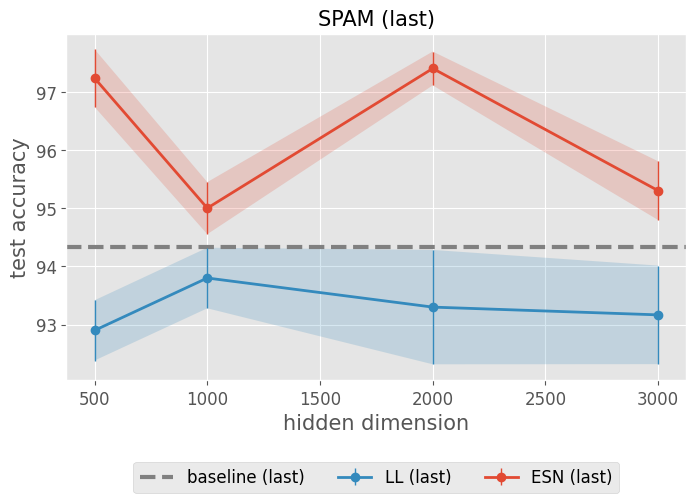

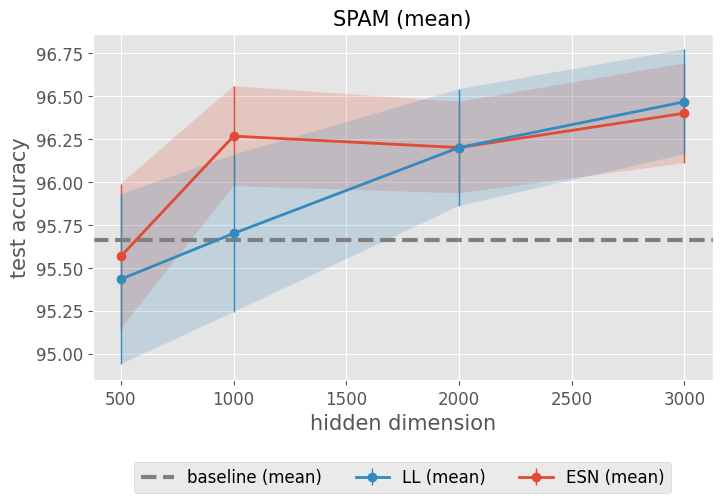

In [6]:
# create plots
RESULTS_PATH = 'C:\\Users\\AJYH\\Desktop\\UNIVERSIDAD\\GII - TI - US\\5o CURSO (2024-2025)\\TFG\esn_torch_virt_env\\esntorch\\notebooks_paper_2022\\ESN_v2\\Results\\ESN_v2' # put your path here

for dataset in ['banking', 'emotion', 'spam']:

    for pooling_strategy in ['last', 'mean']:
            
        RESULTS_FILE = f'{dataset}_results_esn_uniform_{pooling_strategy}-pooling_FINAL.pkl'
        # RESULTS_FILE = f'{dataset}_results_{pooling_strategy}.pkl'
        print('RESULTS FILE:', RESULTS_FILE)
        
        with open(os.path.join(RESULTS_PATH, RESULTS_FILE), 'rb') as fh:
            results_d = pickle.load(fh)
            
        plot_by_ps(dataset, pooling_strategy, results_d)

In [7]:
# RESULTS_PATH
# trec_mean_file = 'trec-6_results_esn_uniform_mean-pooling_FINAL.pkl'
# trec_last_file = 'trec-6_results_esn_uniform_last-pooling_FINAL.pkl'

In [8]:
# with open(os.path.join(RESULTS_PATH, trec_mean_file), 'rb') as fh:
#     results_d_mean = pickle.load(fh)

In [9]:
# results_d_mean

In [10]:
# with open(os.path.join(RESULTS_PATH, trec_last_file), 'rb') as fh:
#     results_d_last = pickle.load(fh)

In [11]:
# results_d_last

In [12]:
# Nueva función: compara el mismo modelo con distintas estrategias de pooling
def plot_by_model(dataset, model_name, results_last, results_mean):
    dims = list(results_last.keys())
    dims.sort()

    model_display = 'ESN' if model_name == 'recurrent_layer' else 'LL'

    acc_bs_last = baselines_d[dataset]['last']
    acc_bs_mean = baselines_d[dataset]['mean']

    acc_model_last = np.array([results_last[x][model_name][0] for x in dims])
    std_model_last = np.array([results_last[x][model_name][1] for x in dims])

    acc_model_mean = np.array([results_mean[x][model_name][0] for x in dims])
    std_model_mean = np.array([results_mean[x][model_name][1] for x in dims])

    fig = plt.figure(figsize=(8, 4.5))
    ax = fig.add_subplot(111)

    # Baselines (línea discontinua para 'last', punteada para 'mean')
    ax.axhline(y=acc_bs_last, linestyle='--', linewidth=3, color='grey', label='baseline (last)', alpha=1)
    ax.axhline(y=acc_bs_mean, linestyle=':',  linewidth=3, color='grey', label='baseline (mean)', alpha=1)

    # Modelo con pooling 'last'
    ax.errorbar(dims, acc_model_last, std_model_last, color='C0', elinewidth=1, linewidth=2,
                label=f'{model_display} (last)', marker='o', alpha=1)
    ax.fill_between(dims, acc_model_last - std_model_last, acc_model_last + std_model_last, alpha=0.2)

    # Modelo con pooling 'mean'
    ax.errorbar(dims, acc_model_mean, std_model_mean, color='C1', elinewidth=1, linewidth=2,
                label=f'{model_display} (mean)', marker='o', alpha=1)
    ax.fill_between(dims, acc_model_mean - std_model_mean, acc_model_mean + std_model_mean,
                    color='C1', alpha=0.2)

    ax.set_title(f'{dataset.upper()} ({model_display})', fontsize=15)
    ax.set_ylabel('test accuracy', fontsize=15)
    ax.set_xlabel('hidden dimension', fontsize=15)
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

    # Reordenar leyenda: [baseline_last, model_last, baseline_mean, model_mean]
    handles, labels = ax.get_legend_handles_labels()
    handles = [handles[0], handles[2], handles[1], handles[3]]
    labels  = [labels[0],  labels[2],  labels[1],  labels[3]]

    plt.legend(handles, labels, loc='lower center', prop={'size': 12}, ncol=2, bbox_to_anchor=(0.5, -0.45))
    plt.savefig(f'plots/{dataset}-{model_display.lower()}.pdf', bbox_inches='tight')

RESULTS FILE: banking_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: banking_results_esn_uniform_mean-pooling_FINAL.pkl
RESULTS FILE: emotion_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: emotion_results_esn_uniform_mean-pooling_FINAL.pkl
RESULTS FILE: spam_results_esn_uniform_last-pooling_FINAL.pkl
RESULTS FILE: spam_results_esn_uniform_mean-pooling_FINAL.pkl


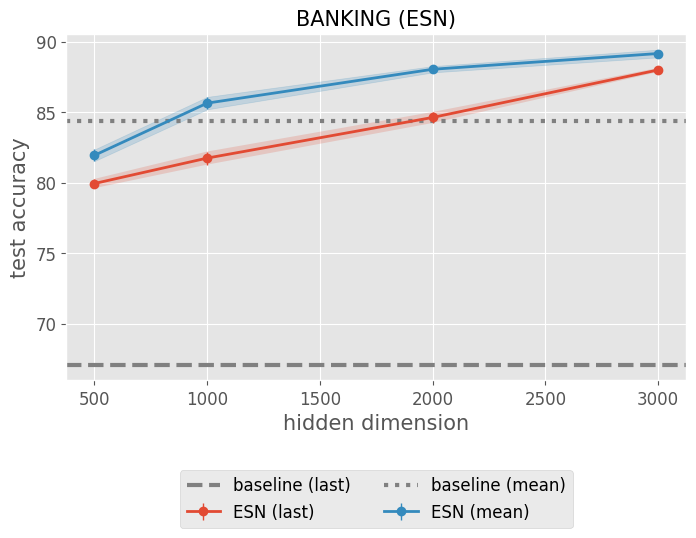

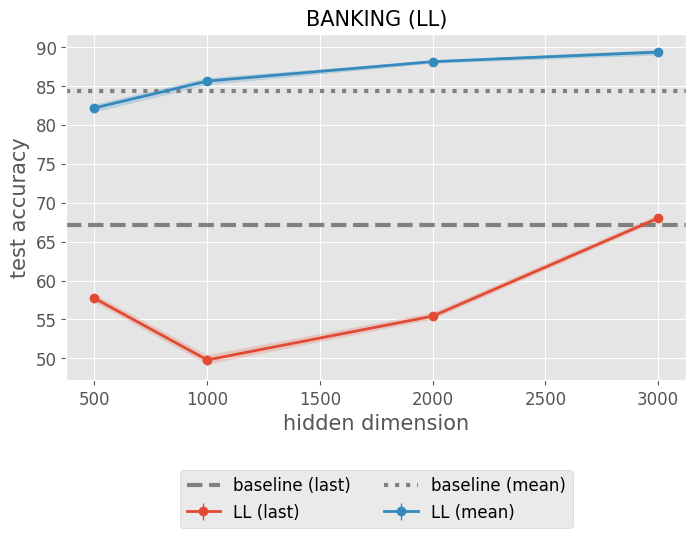

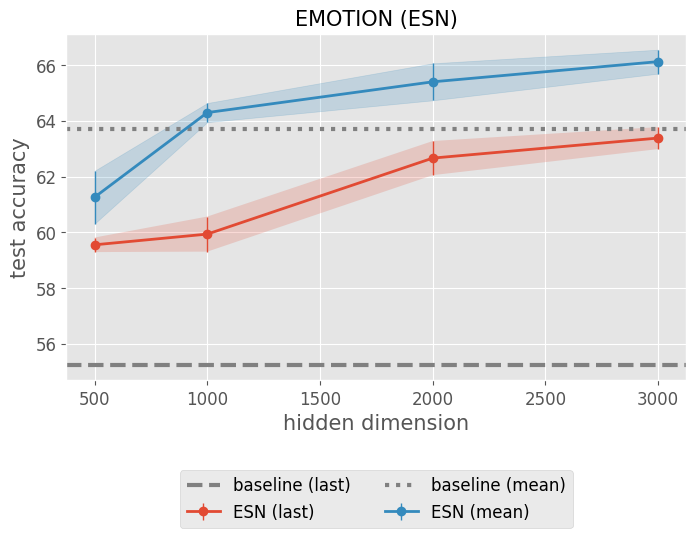

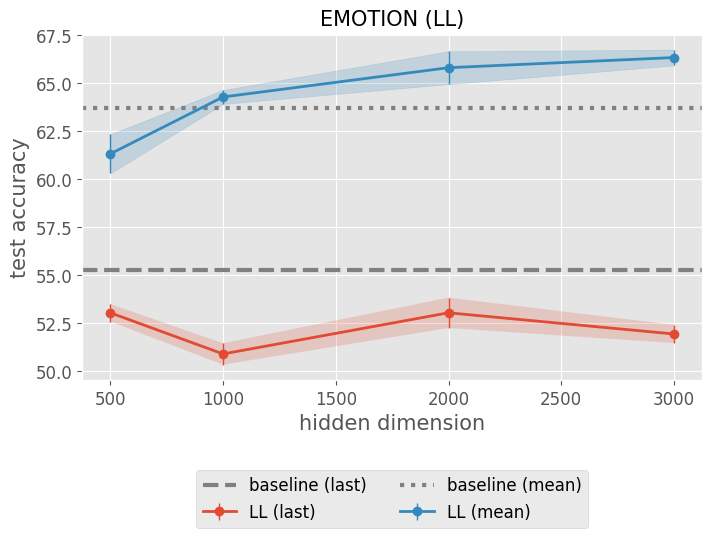

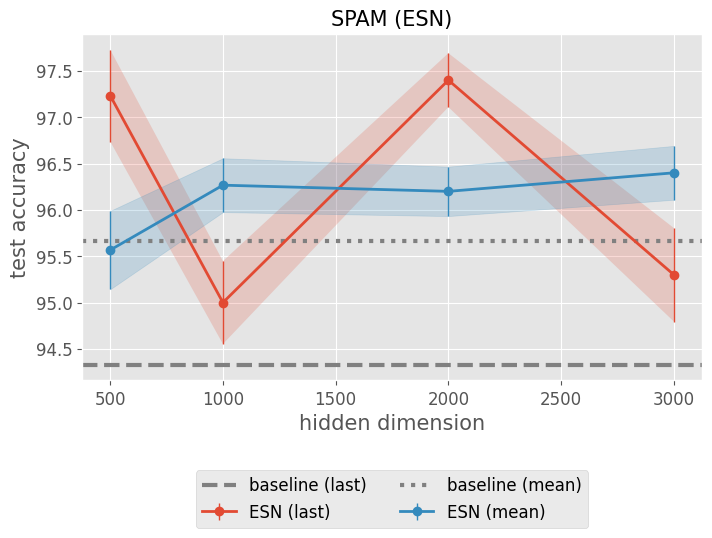

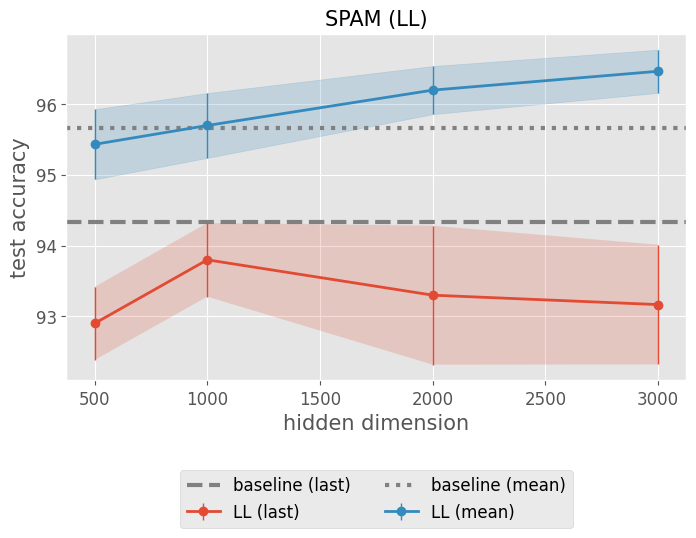

In [13]:
# Generar las gráficas por modelo (requiere RESULTS_PATH definido en la celda anterior)
for dataset in ['banking', 'emotion', 'spam']:

    results_by_pooling = {}
    for pooling_strategy in ['last', 'mean']:
        RESULTS_FILE = f'{dataset}_results_esn_uniform_{pooling_strategy}-pooling_FINAL.pkl'
        print('RESULTS FILE:', RESULTS_FILE)
        with open(os.path.join(RESULTS_PATH, RESULTS_FILE), 'rb') as fh:
            results_by_pooling[pooling_strategy] = pickle.load(fh)

    for model_name in ['recurrent_layer', 'linear_layer']:
        plot_by_model(dataset, model_name, results_by_pooling['last'], results_by_pooling['mean'])

In [17]:
# # RESULTS_PATH
# trec_mean_file = 'trec-6_results_esn_uniform_mean-pooling_FINAL.pkl'
# trec_last_file = 'trec-6_results_esn_uniform_last-pooling_FINAL.pkl'

In [18]:
# with open(os.path.join(RESULTS_PATH, trec_mean_file), 'rb') as fh:
#     results_d_mean = pickle.load(fh)

In [19]:
# results_d_mean

In [20]:
# with open(os.path.join(RESULTS_PATH, trec_last_file), 'rb') as fh:
#     results_d_last = pickle.load(fh)

In [21]:
# results_d_last